# Hotel Booking Cancellation Prediction (simple version)
Creative Institute of Data Science – every section is labelled with its question number.

In Colab, change the file path in the first data cell.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

## Q1–Q5: Load data, shape, data types, missing values

In [2]:
df = pd.read_csv("/mnt/user-data/uploads/hotel_bookings.csv")

print("Q1: first 5 rows")
display(df.head())

print("Q2: rows and columns:", df.shape)

print("Q3: column names and data types")
print(df.dtypes)

print("Q4: missing values")
missing = df.isnull().sum()
print(missing[missing > 0])

print("Q5: missing percentage")
print((missing[missing > 0] / len(df) * 100).round(2))

Q1: first 5 rows


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Q2: rows and columns: (119390, 32)
Q3: column names and data types
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_t

## Q6: Handle missing values
- `children` → 0
- `country` → "Unknown"
- `agent` → 0 (no agent)
- `company` → 94% missing, so drop it (keep a 0/1 flag `has_company`)

In [3]:
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0)
df["has_company"] = df["company"].notnull().astype(int)
df = df.drop(columns="company")
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


## Q7–Q8: Duplicate records

In [4]:
print("Q7: duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Q8: shape after removing duplicates:", df.shape)

Q7: duplicate rows: 31998
Q8: shape after removing duplicates: (87392, 32)


## Q9–Q11: Zero guests, total_guests, invalid bookings

In [5]:
print("Q9: adults = 0   :", (df["adults"] == 0).sum())
print("Q9: children = 0 :", (df["children"] == 0).sum())
print("Q9: babies = 0   :", (df["babies"] == 0).sum())

df["total_guests"] = df["adults"] + df["children"] + df["babies"]      # Q10

# Q11: invalid bookings = no guests at all, negative price, or one impossible price (5400)
print("Zero guests:", (df["total_guests"] == 0).sum())
print("Negative adr:", (df["adr"] < 0).sum())
print("adr >= 5000:", (df["adr"] >= 5000).sum())
df = df[df["total_guests"] > 0]
df = df[(df["adr"] >= 0) & (df["adr"] < 5000)]
df = df.reset_index(drop=True)
print("Shape after removing invalid bookings:", df.shape)

Q9: adults = 0   : 385
Q9: children = 0 : 79028
Q9: babies = 0   : 86478
Zero guests: 166
Negative adr: 1
adr >= 5000: 1
Shape after removing invalid bookings: (87224, 33)


## Q12–Q13: Outliers using IQR

lead_time: lower=-160.0, upper=296.0, outliers=2394 (2.74%)
adr: lower=-20.5, upper=226.9, outliers=2507 (2.87%)
stays_in_week_nights: lower=-3.5, upper=8.5, outliers=1514 (1.74%)
stays_in_weekend_nights: lower=-3.0, upper=5.0, outliers=213 (0.24%)


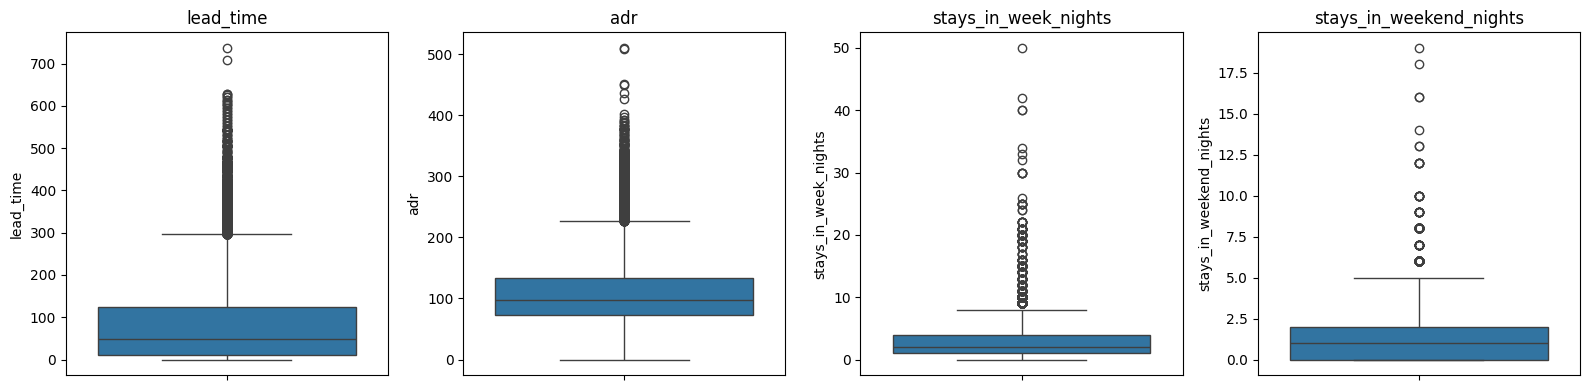

In [6]:
cols = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights"]
for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: lower={lower:.1f}, upper={upper:.1f}, outliers={n_out} ({n_out/len(df)*100:.2f}%)")

plt.figure(figsize=(16, 4))
for i, col in enumerate(cols):
    plt.subplot(1, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

**Q13 analysis:** the outliers are real values (very early bookings, long holidays, expensive rooms in peak season), not mistakes. Tree models are not affected much by extreme values, so we keep them.

## Q14–Q18: New features

In [7]:
df["total_stay"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]        # Q14
df["is_family"] = ((df["children"] + df["babies"]) > 0).astype(int)                  # Q15
df["room_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)   # Q16

# Q17: proper arrival date
months = {"January":1,"February":2,"March":3,"April":4,"May":5,"June":6,"July":7,
          "August":8,"September":9,"October":10,"November":11,"December":12}
df["arrival_month_num"] = df["arrival_date_month"].map(months)
df["arrival_date"] = pd.to_datetime(dict(year=df["arrival_date_year"],
                                         month=df["arrival_month_num"],
                                         day=df["arrival_date_day_of_month"]))

# Q18: date-based features
df["arrival_dayofweek"] = df["arrival_date"].dt.dayofweek      # 0 = Monday
df["arrival_quarter"] = df["arrival_date"].dt.quarter
df["is_weekend_arrival"] = (df["arrival_dayofweek"] >= 5).astype(int)
df["booking_date"] = df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
df["booking_month"] = df["booking_date"].dt.month
df[["arrival_date", "booking_date", "total_stay", "total_guests", "is_family", "room_changed"]].head()

,arrival_date,booking_date,total_stay,total_guests,is_family,room_changed
0,2015-07-01,2014-07-24,0,2.0,0,0
1,2015-07-01,2013-06-24,0,2.0,0,0
2,2015-07-01,2015-06-24,1,1.0,0,1
3,2015-07-01,2015-06-18,1,1.0,0,0
4,2015-07-01,2015-06-17,2,2.0,0,0


## Q19–Q20: Cancellation percentage and balance

Q19: cancellation %: 27.52
is_canceled
0    63216
1    24008
Name: count, dtype: int64


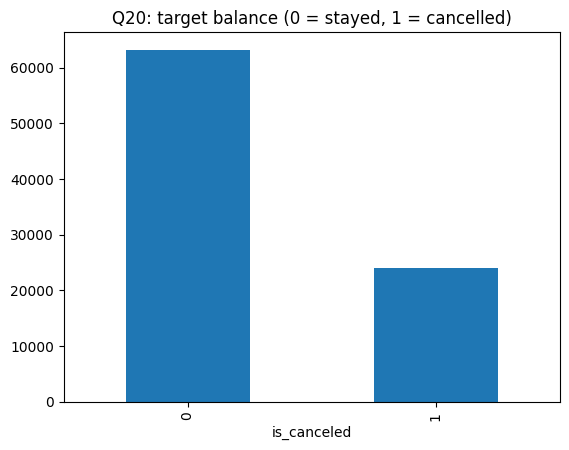

In [8]:
print("Q19: cancellation %:", round(df["is_canceled"].mean() * 100, 2))
print(df["is_canceled"].value_counts())
df["is_canceled"].value_counts().plot(kind="bar")
plt.title("Q20: target balance (0 = stayed, 1 = cancelled)")
plt.show()

**Q20:** about 72% stayed and 28% cancelled, so the target is moderately imbalanced (not severe). We use a stratified split and look at F1 and ROC-AUC as well as accuracy.

## Q21–Q29: Cancellation rate analysis

In [9]:
# cancellation rate (%) = mean of is_canceled x 100
for col in ["hotel", "market_segment", "customer_type", "deposit_type"]:        # Q21–Q24
    print("Cancellation rate by", col)
    print((df.groupby(col)["is_canceled"].mean() * 100).round(2).sort_values(ascending=False))
    print()

Cancellation rate by hotel
hotel
City Hotel      30.10
Resort Hotel    23.49
Name: is_canceled, dtype: float64

Cancellation rate by market_segment
market_segment
Undefined        100.00
Online TA         35.38
Groups            27.07
Aviation          19.91
Offline TA/TO     14.84
Direct            14.75
Complementary     12.28
Corporate         12.13
Name: is_canceled, dtype: float64

Cancellation rate by customer_type
customer_type
Transient          30.14
Contract           16.33
Transient-Party    15.25
Group               9.80
Name: is_canceled, dtype: float64

Cancellation rate by deposit_type
deposit_type
Non Refund    94.70
No Deposit    26.72
Refundable    24.30
Name: is_canceled, dtype: float64



In [10]:
# Q25: lead_time vs cancellation
df["lead_group"] = pd.cut(df["lead_time"], [-1, 7, 30, 90, 180, 365, 800],
                          labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"])
print("Q25: cancellation % by lead time")
print((df.groupby("lead_group")["is_canceled"].mean() * 100).round(2))
print(df.groupby("is_canceled")["lead_time"].mean().round(1))

# Q26: adr vs cancellation (5 equal-size price groups)
df["adr_group"] = pd.qcut(df["adr"], 5)
print("\nQ26: cancellation % by adr group")
print((df.groupby("adr_group")["is_canceled"].mean() * 100).round(2))

# Q27, Q28, Q29
print("\nQ27: special requests")
print((df.groupby("total_of_special_requests")["is_canceled"].mean() * 100).round(2))
print("\nQ28: previous cancellations")
print((df.groupby("previous_cancellations")["is_canceled"].mean() * 100).round(2).head(5))
print("\nQ29: repeated guest (0 = new, 1 = repeated)")
print((df.groupby("is_repeated_guest")["is_canceled"].mean() * 100).round(2))

df["lead_group"].value_counts()   # (helper columns are dropped later)

Q25: cancellation % by lead time
lead_group
0-7         8.42
8-30       25.39
31-90      32.04
91-180     35.01
181-365    39.69
365+       40.78
Name: is_canceled, dtype: float64
is_canceled
0     70.2
1    105.7
Name: lead_time, dtype: float64

Q26: cancellation % by adr group
adr_group
(-0.001, 65.0]    17.40
(65.0, 88.4]      24.07
(88.4, 110.5]     28.76
(110.5, 144.0]    32.94
(144.0, 510.0]    34.51
Name: is_canceled, dtype: float64

Q27: special requests
total_of_special_requests
0    33.25
1    22.44
2    21.32
3    17.11
4    10.62
5     5.56
Name: is_canceled, dtype: float64

Q28: previous cancellations
previous_cancellations
0    26.73
1    76.16
2    30.91
3    26.23
4    20.00
Name: is_canceled, dtype: float64

Q29: repeated guest (0 = new, 1 = repeated)
is_repeated_guest
0    28.32
1     7.73
Name: is_canceled, dtype: float64


lead_group
31-90      22719
91-180     18224
0-7        18199
8-30       16326
181-365    11192
365+         564
Name: count, dtype: int64

## Q30–Q31: Countries

In [11]:
print("Q30: top 10 countries by bookings")
print(df["country"].value_counts().head(10))

country_stats = df.groupby("country")["is_canceled"].agg(["count", "mean"])
country_stats["cancel_%"] = (country_stats["mean"] * 100).round(2)
print("\nQ31: cancellation % for countries with 500+ bookings")
print(country_stats[country_stats["count"] >= 500].sort_values("cancel_%", ascending=False)[["count", "cancel_%"]])

Q30: top 10 countries by bookings
country
PRT    27350
GBR    10423
FRA     8823
ESP     7244
DEU     5385
ITA     3061
IRL     3015
BEL     2081
BRA     1993
NLD     1910
Name: count, dtype: int64

Q31: cancellation % for countries with 500+ bookings
         count  cancel_%
country                 
CHN        816     48.04
RUS        559     39.71
BRA       1993     36.48
PRT      27350     35.76
ITA       3061     35.12
NOR        515     28.16
ESP       7244     25.70
USA       1871     24.53
CHE       1566     24.52
IRL       3015     22.16
POL        764     21.47
SWE        833     21.25
CN        1093     20.59
BEL       2081     19.75
FRA       8823     19.63
DEU       5385     19.55
GBR      10423     19.03
NLD       1910     18.32
AUT        947     17.95


## Q32–Q35: Column types, unnecessary columns, data leakage

In [12]:
print("Q32: categorical columns:", df.select_dtypes(include="object").columns.tolist())
print("Q32: numerical columns  :", df.select_dtypes(exclude="object").columns.tolist())

# Q34: how do the suspicious columns relate to the target?
print("\nreservation_status vs is_canceled")
print(pd.crosstab(df["reservation_status"], df["is_canceled"]))
print("\nAverage parking spaces:", df.groupby("is_canceled")["required_car_parking_spaces"].mean().round(3).to_dict())
print("room_changed rate     :", df.groupby("is_canceled")["room_changed"].mean().round(3).to_dict())

Q32: categorical columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']
Q32: numerical columns  : ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'has_company', 'total_guests', 'total_stay', 'is_family', 'room_changed', 'arrival_month_num', 'arrival_date', 'arrival_dayofweek', 'arrival_quarter', 'is_weekend_arrival', 'booking_date', 'booking_month', 'lead_group', 'adr_group']

reservation_status vs is_canceled
is_canceled             0      1
reservation_status              
Cance

**Q33 – unnecessary columns:** `arrival_date`, `booking_date` (raw dates, we already made month/day features), `arrival_date_month` (we have the number), `lead_group`, `adr_group` (only used for analysis).

**Q34 – leakage columns** (they reveal the answer or are only known after the booking outcome):
- `reservation_status` – it literally says Canceled / Check-Out / No-Show
- `reservation_status_date` – date of the final status
- `required_car_parking_spaces` – cancelled bookings never have parking (always 0)
- `assigned_room_type` and `room_changed` – assigned at check-in; cancelled bookings almost never change room

**Q35:** we drop all of them below.

In [13]:
leakage = ["reservation_status", "reservation_status_date", "required_car_parking_spaces",
           "assigned_room_type", "room_changed"]
unneeded = ["arrival_date", "booking_date", "arrival_date_month", "lead_group", "adr_group"]
df_model = df.drop(columns=leakage + unneeded)
print("Columns left:", df_model.shape[1])

Columns left: 35


## Q36–Q38: Encoding, X and y, train-test split

In [14]:
# Q36: encoding
# country has ~170 values, so one-hot would create too many columns -> use label codes
df_model["country"] = df_model["country"].astype("category").cat.codes
df_model["agent"] = df_model["agent"].astype(int)

# keep a copy with text categories for CatBoost (Q55)
cat_cols = ["hotel", "meal", "market_segment", "distribution_channel",
            "reserved_room_type", "deposit_type", "customer_type"]
df_cat = df_model.copy()
df_cat[cat_cols] = df_cat[cat_cols].astype(str)

# one-hot encoding for the other models
df_encoded = pd.get_dummies(df_model, columns=cat_cols, dtype=int)

# Q37: X and y
y = df_encoded["is_canceled"]
X = df_encoded.drop(columns="is_canceled")
X_cat = df_cat.drop(columns="is_canceled")
print("X:", X.shape, " y:", y.shape)

# Q38: train/test split (80/20, same split for both versions)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
Xc_train = X_cat.loc[X_train.index]
Xc_test = X_cat.loc[X_test.index]
print("Train:", X_train.shape, " Test:", X_test.shape)

# small sample of the training data, used only to make hyper-parameter tuning faster
X_small = X_train.sample(20000, random_state=42)
Xc_small = Xc_train.loc[X_small.index]
y_small = y_train.loc[X_small.index]

X: (87224, 63)  y: (87224,)


Train: (69779, 63)  Test: (17445, 63)


## Helper: train a model, time it and calculate all metrics

In [15]:
results = []      # one row per model
models = {}       # fitted models
probs = {}        # predicted probabilities on test data (for ROC curves)

def evaluate(name, model, Xtr, Xte, **fit_params):
    start = time.time()
    model.fit(Xtr, y_train, **fit_params)
    train_time = time.time() - start

    pred_train = model.predict(Xtr)
    pred_test = model.predict(Xte)
    prob_test = model.predict_proba(Xte)[:, 1]

    row = {"Model": name,
           "Train Acc": accuracy_score(y_train, pred_train),
           "Test Acc": accuracy_score(y_test, pred_test),
           "Precision": precision_score(y_test, pred_test),
           "Recall": recall_score(y_test, pred_test),
           "F1": f1_score(y_test, pred_test),
           "ROC-AUC": roc_auc_score(y_test, prob_test),
           "Time (s)": train_time}
    results.append(row)
    models[name] = model
    probs[name] = prob_test
    print(pd.DataFrame([row]).round(4).to_string(index=False))

## Q39–Q41: Decision Tree

In [16]:
evaluate("Decision Tree", DecisionTreeClassifier(random_state=42), X_train, X_test)
r = results[-1]
print("\nQ41: train accuracy", round(r["Train Acc"], 4), "vs test accuracy", round(r["Test Acc"], 4))
print("Gap =", round(r["Train Acc"] - r["Test Acc"], 4), "-> big gap means the tree is overfitting")

        Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
Decision Tree     0.9971    0.7892     0.6151  0.6256 0.6203   0.7395    1.1433

Q41: train accuracy 0.9971 vs test accuracy 0.7892
Gap = 0.208 -> big gap means the tree is overfitting


## Q42–Q43: Random Forest

In [17]:
evaluate("Random Forest", RandomForestClassifier(n_estimators=100, random_state=42), X_train, X_test)
print()
print(pd.DataFrame(results).round(4).to_string(index=False))

        Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
Random Forest     0.9971    0.8351     0.7521  0.5983 0.6664   0.8909    8.8648

        Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
Decision Tree     0.9971    0.7892     0.6151  0.6256 0.6203   0.7395    1.1433
Random Forest     0.9971    0.8351     0.7521  0.5983 0.6664   0.8909    8.8648


**Q43 – Random Forest vs Decision Tree:** averaging 100 trees raises test accuracy from 78.9% to 83.5% and ROC-AUC from 0.740 to 0.891. Random Forest still scores 99.7% on training data, so a 16-point gap remains: it is much better than one tree, but still overfits.

## Q44–Q46: AdaBoost

In [18]:
evaluate("AdaBoost", AdaBoostClassifier(random_state=42), X_train, X_test)

# Q45: tune n_estimators and learning_rate
grid = {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 0.5, 1.0]}
search = GridSearchCV(AdaBoostClassifier(random_state=42), grid, cv=3, scoring="roc_auc")
search.fit(X_small, y_small)
print("\nBest parameters:", search.best_params_)
best_params = {"AdaBoost": search.best_params_}

evaluate("AdaBoost (tuned)", AdaBoostClassifier(random_state=42, **search.best_params_), X_train, X_test)

   Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
AdaBoost     0.7792      0.78     0.6733    0.39 0.4939   0.8206    2.6236



Best parameters: {'learning_rate': 1.0, 'n_estimators': 200}


           Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
AdaBoost (tuned)     0.7942    0.7971     0.6928  0.4725 0.5618   0.8411   10.3493


**Q46 – AdaBoost vs Decision Tree:** AdaBoost has a much higher ROC-AUC (0.841 vs 0.740) and slightly higher test accuracy (79.7% vs 78.9%), and it does not overfit (train 79.4%, test 79.7%). The Decision Tree only wins on recall (62.6% vs 47.3%), but it memorised the training data (99.7%).

## Q47–Q49: Gradient Boosting

In [19]:
evaluate("Gradient Boosting", GradientBoostingClassifier(random_state=42), X_train, X_test)

# Q48: tune n_estimators, learning_rate, max_depth
grid = {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]}
search = GridSearchCV(GradientBoostingClassifier(random_state=42), grid, cv=3, scoring="roc_auc")
search.fit(X_small, y_small)
print("\nBest parameters:", search.best_params_)
best_params["Gradient Boosting"] = search.best_params_

evaluate("Gradient Boosting (tuned)", GradientBoostingClassifier(random_state=42, **search.best_params_), X_train, X_test)

            Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
Gradient Boosting     0.8196    0.8197      0.739  0.5331 0.6194   0.8758    11.457



Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}


                    Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
Gradient Boosting (tuned)       0.85    0.8383     0.7419  0.6327 0.6829   0.9002   37.9965


**Q49 – AdaBoost vs Gradient Boosting:** Gradient Boosting is better on every metric: ROC-AUC 0.900 vs 0.841, accuracy 83.8% vs 79.7%, recall 63.3% vs 47.3%. The price is time: about 38 s vs 10 s. AdaBoost's train and test accuracy are almost the same, so it is *underfitting* (its one-split trees are too simple).

## Q50–Q51: XGBoost

In [20]:
evaluate("XGBoost", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                                  eval_metric="logloss", random_state=42), X_train, X_test)

# Q51: tune 8 parameters. The grid is big, so RandomizedSearchCV tries 10 random combinations.
grid = {"n_estimators": [200, 300, 500], "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [4, 6, 8], "gamma": [0, 0.5, 1],
        "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_alpha": [0, 0.1, 1], "reg_lambda": [1, 2, 5]}
search = RandomizedSearchCV(XGBClassifier(eval_metric="logloss", random_state=42), grid,
                            n_iter=10, cv=3, scoring="roc_auc", random_state=42)
search.fit(X_small, y_small)
print("\nBest parameters:", search.best_params_)
best_params["XGBoost"] = search.best_params_

evaluate("XGBoost (tuned)", XGBClassifier(eval_metric="logloss", random_state=42, **search.best_params_), X_train, X_test)

  Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
XGBoost     0.8687    0.8433     0.7443   0.656 0.6974   0.9057    2.2061



Best parameters: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.05, 'gamma': 1, 'colsample_bytree': 1.0}


          Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
XGBoost (tuned)     0.8802     0.845     0.7485  0.6581 0.7004    0.909    3.0984


## Q52–Q53: LightGBM

In [21]:
evaluate("LightGBM", LGBMClassifier(n_estimators=300, learning_rate=0.1, random_state=42, verbose=-1), X_train, X_test)

# Q53: tune n_estimators, learning_rate, num_leaves, max_depth
grid = {"n_estimators": [200, 300], "learning_rate": [0.05, 0.1],
        "num_leaves": [31, 63], "max_depth": [8, 12]}
search = GridSearchCV(LGBMClassifier(random_state=42, verbose=-1), grid, cv=3, scoring="roc_auc")
search.fit(X_small, y_small)
print("\nBest parameters:", search.best_params_)
best_params["LightGBM"] = search.best_params_

evaluate("LightGBM (tuned)", LGBMClassifier(random_state=42, verbose=-1, **search.best_params_), X_train, X_test)

   Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
LightGBM     0.8702    0.8437     0.7448  0.6574 0.6984   0.9071    1.9512



Best parameters: {'learning_rate': 0.05, 'max_depth': 12, 'n_estimators': 200, 'num_leaves': 63}


           Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
LightGBM (tuned)     0.8599    0.8435     0.7463  0.6535 0.6968   0.9062    1.5962


## Q54–Q56: CatBoost

In [22]:
# Q54: CatBoost on the one-hot encoded data
evaluate("CatBoost (encoded)", CatBoostClassifier(iterations=300, learning_rate=0.1, depth=6,
                                                  verbose=0, random_seed=42), X_train, X_test)

# Q55: CatBoost using the text categorical columns directly
evaluate("CatBoost (categorical)", CatBoostClassifier(iterations=300, learning_rate=0.1, depth=6,
                                                      verbose=0, random_seed=42),
         Xc_train, Xc_test, cat_features=cat_cols)

# Q56: tune iterations, learning_rate, depth, l2_leaf_reg
grid = {"iterations": [200, 300], "learning_rate": [0.05, 0.1],
        "depth": [4, 6, 8], "l2_leaf_reg": [1, 3, 9]}
search = RandomizedSearchCV(CatBoostClassifier(verbose=0, random_seed=42), grid,
                            n_iter=6, cv=3, scoring="roc_auc", random_state=42)
search.fit(Xc_small, y_small, cat_features=cat_cols)
print("\nBest parameters:", search.best_params_)
best_params["CatBoost"] = search.best_params_

evaluate("CatBoost (tuned)", CatBoostClassifier(verbose=0, random_seed=42, **search.best_params_),
         Xc_train, Xc_test, cat_features=cat_cols)

             Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
CatBoost (encoded)     0.8499    0.8401     0.7459  0.6358 0.6865   0.9023    4.5454


                 Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
CatBoost (categorical)     0.8483    0.8398     0.7455  0.6349 0.6858   0.9021   24.0209



Best parameters: {'learning_rate': 0.1, 'l2_leaf_reg': 9, 'iterations': 300, 'depth': 8}


           Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC  Time (s)
CatBoost (tuned)     0.8581    0.8423     0.7491  0.6422 0.6916   0.9042    32.545


## Q57–Q59, Q74: Comparison table of all models (with training time)

In [23]:
table = pd.DataFrame(results).set_index("Model")
table.round(4)

,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC,Time (s)
Model,,,,,,,
Decision Tree,0.9971,0.7892,0.6151,0.6256,0.6203,0.7395,1.1433
Random Forest,0.9971,0.8351,0.7521,0.5983,0.6664,0.8909,8.8648
AdaBoost,0.7792,0.7800,0.6733,0.3900,0.4939,0.8206,2.6236
AdaBoost (tuned),0.7942,0.7971,0.6928,0.4725,0.5618,0.8411,10.3493
Gradient Boosting,0.8196,0.8197,0.7390,0.5331,0.6194,0.8758,11.4570
Gradient Boosting (tuned),0.8500,0.8383,0.7419,0.6327,0.6829,0.9002,37.9965
XGBoost,0.8687,0.8433,0.7443,0.6560,0.6974,0.9057,2.2061
XGBoost (tuned),0.8802,0.8450,0.7485,0.6581,0.7004,0.9090,3.0984
LightGBM,0.8702,0.8437,0.7448,0.6574,0.6984,0.9071,1.9512


## Q60: Confusion matrices

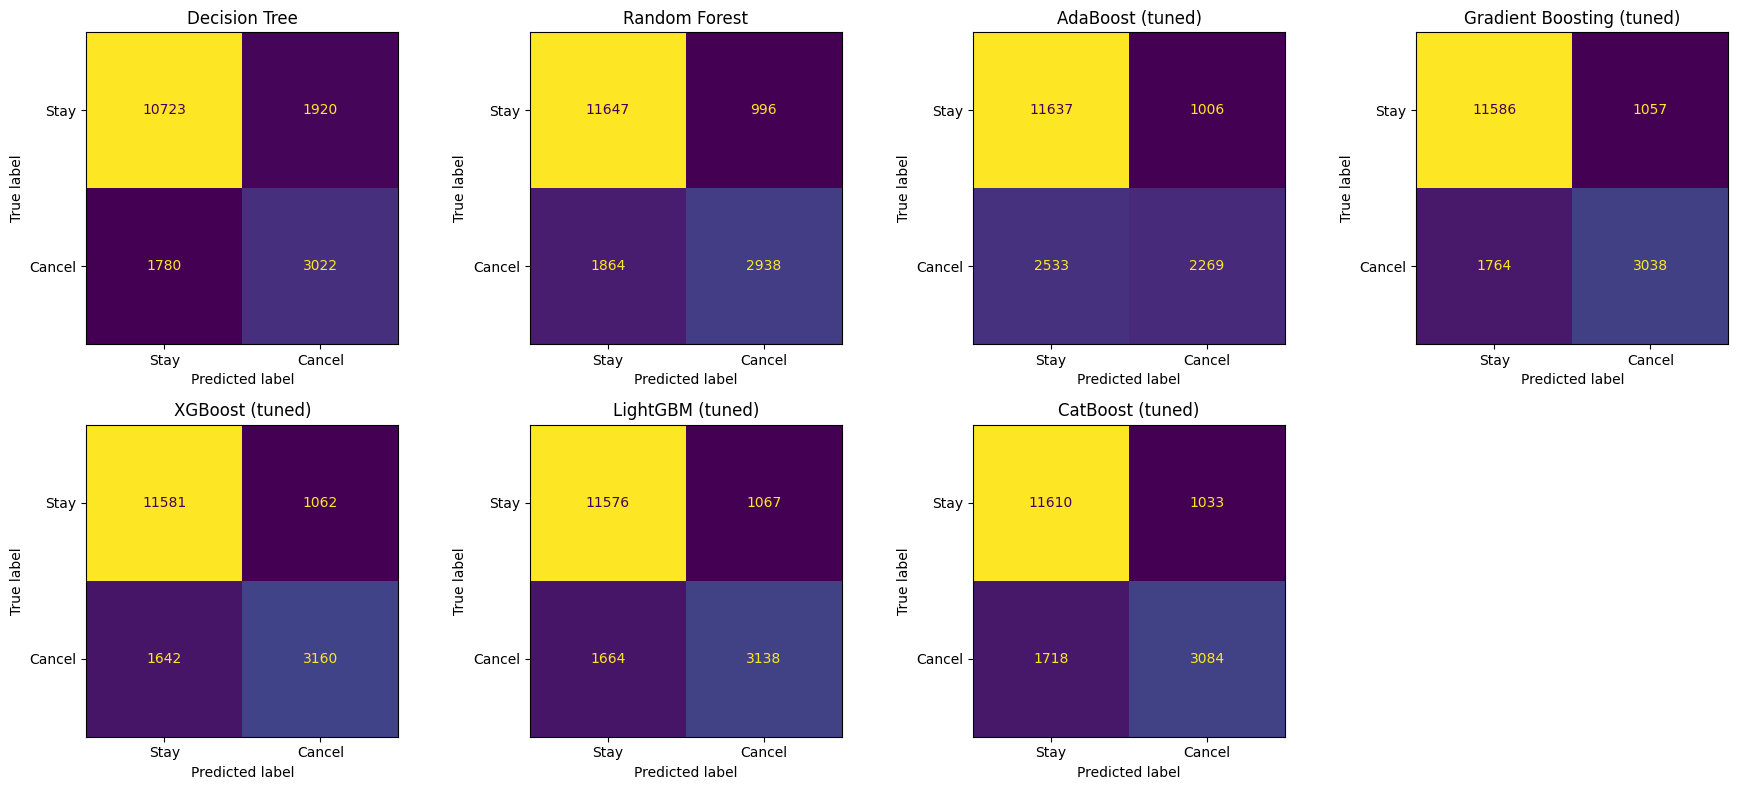

In [24]:
final_models = ["Decision Tree", "Random Forest", "AdaBoost (tuned)", "Gradient Boosting (tuned)",
                "XGBoost (tuned)", "LightGBM (tuned)", "CatBoost (tuned)"]

plt.figure(figsize=(18, 8))
for i, name in enumerate(final_models):
    plt.subplot(2, 4, i + 1)
    pred = (probs[name] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Cancel"]).plot(ax=plt.gca(), colorbar=False)
    plt.title(name)
plt.tight_layout()
plt.show()

## Q61–Q62: 5-fold cross validation

In [25]:
cv_rows = []
for name in final_models:
    model = models[name]
    if "CatBoost" in name:
        scores = cross_validate(model, Xc_train, y_train, cv=5, scoring=["accuracy", "roc_auc"],
                                params={"cat_features": cat_cols})
    else:
        scores = cross_validate(model, X_train, y_train, cv=5, scoring=["accuracy", "roc_auc"])
    cv_rows.append({"Model": name,
                    "CV Accuracy": scores["test_accuracy"].mean(),
                    "CV ROC-AUC": scores["test_roc_auc"].mean(),
                    "CV AUC std": scores["test_roc_auc"].std()})
    print(name, "done")

cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.round(4)

Decision Tree done


Random Forest done


AdaBoost (tuned) done


Gradient Boosting (tuned) done


XGBoost (tuned) done


LightGBM (tuned) done


CatBoost (tuned) done


,CV Accuracy,CV ROC-AUC,CV AUC std
Model,,,
Decision Tree,0.7813,0.7298,0.0022
Random Forest,0.8346,0.8871,0.0024
AdaBoost (tuned),0.7945,0.8383,0.0011
Gradient Boosting (tuned),0.8375,0.8961,0.0026
XGBoost (tuned),0.8430,0.9048,0.0021
LightGBM (tuned),0.8407,0.9026,0.0017
CatBoost (tuned),0.8406,0.9013,0.0017


## Q63–Q65: Best parameters and before/after tuning
(The tuning for XGBoost, LightGBM and CatBoost was done in Q51, Q53 and Q56.)

In [26]:
print("Q64: best parameters")
for name, p in best_params.items():
    print(name, "->", p)

print("\nQ65: before vs after tuning (test data)")
pairs = [("AdaBoost", "AdaBoost (tuned)"), ("Gradient Boosting", "Gradient Boosting (tuned)"),
         ("XGBoost", "XGBoost (tuned)"), ("LightGBM", "LightGBM (tuned)"),
         ("CatBoost (categorical)", "CatBoost (tuned)")]
rows = []
for before, after in pairs:
    rows.append({"Model": after.replace(" (tuned)", ""),
                 "Acc before": table.loc[before, "Test Acc"], "Acc after": table.loc[after, "Test Acc"],
                 "AUC before": table.loc[before, "ROC-AUC"], "AUC after": table.loc[after, "ROC-AUC"]})
pd.DataFrame(rows).set_index("Model").round(4)

Q64: best parameters
AdaBoost -> {'learning_rate': 1.0, 'n_estimators': 200}
Gradient Boosting -> {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
XGBoost -> {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.05, 'gamma': 1, 'colsample_bytree': 1.0}
LightGBM -> {'learning_rate': 0.05, 'max_depth': 12, 'n_estimators': 200, 'num_leaves': 63}
CatBoost -> {'learning_rate': 0.1, 'l2_leaf_reg': 9, 'iterations': 300, 'depth': 8}

Q65: before vs after tuning (test data)


,Acc before,Acc after,AUC before,AUC after
Model,,,,
AdaBoost,0.7800,0.7971,0.8206,0.8411
Gradient Boosting,0.8197,0.8383,0.8758,0.9002
XGBoost,0.8433,0.8450,0.9057,0.9090
LightGBM,0.8437,0.8435,0.9071,0.9062
CatBoost,0.8398,0.8423,0.9021,0.9042


## Q66–Q67: Feature importance (XGBoost tuned)

deposit_type_Non Refund         0.1349
market_segment_Online TA        0.1337
deposit_type_No Deposit         0.0601
total_of_special_requests       0.0510
market_segment_Offline TA/TO    0.0464
market_segment_Direct           0.0373
country                         0.0353
customer_type_Transient         0.0322
previous_cancellations          0.0295
agent                           0.0238
dtype: float32


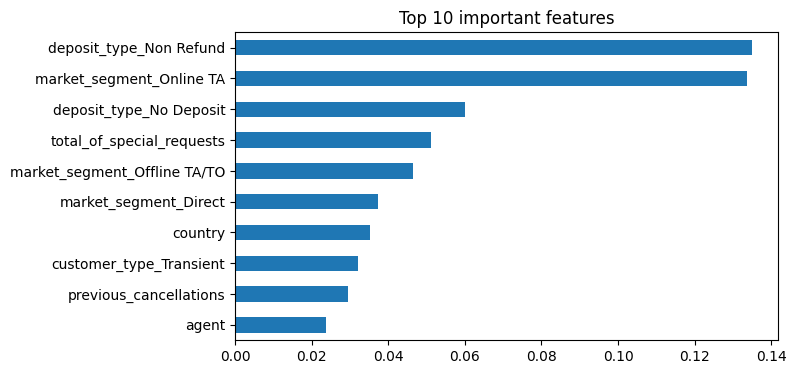

In [27]:
importance = pd.Series(models["XGBoost (tuned)"].feature_importances_, index=X_train.columns)
top10 = importance.sort_values(ascending=False).head(10)
print(top10.round(4))
top10.sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Top 10 important features")
plt.show()

## Q68–Q69: ROC curves for the boosting models

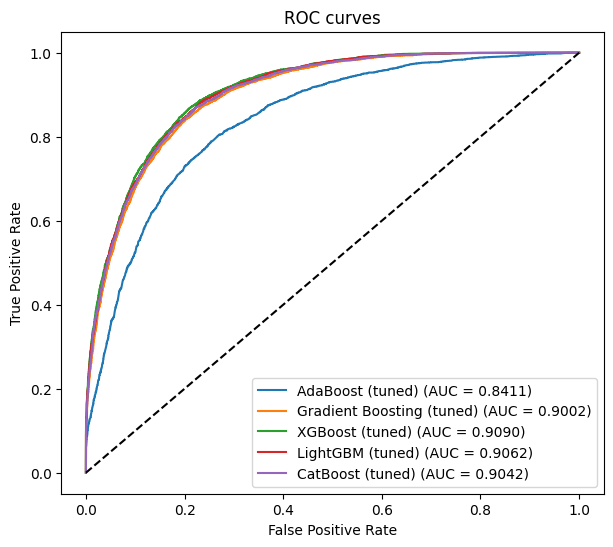

In [28]:
boosting = ["AdaBoost (tuned)", "Gradient Boosting (tuned)", "XGBoost (tuned)", "LightGBM (tuned)", "CatBoost (tuned)"]
plt.figure(figsize=(7, 6))
for name in boosting:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs[name]):.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC curves")
plt.legend()
plt.show()

## Q70–Q71: Best model and overfitting check

In [29]:
final_table = table.loc[final_models]
best_name = final_table["ROC-AUC"].idxmax()
print("Q70: best model:", best_name)
print(final_table.loc[best_name].round(4))

print("\nQ71: train accuracy vs test accuracy for every final model")
check = final_table[["Train Acc", "Test Acc"]].copy()
check["Gap"] = check["Train Acc"] - check["Test Acc"]
check.round(4)

Q70: best model: XGBoost (tuned)
Train Acc    0.8802
Test Acc     0.8450
Precision    0.7485
Recall       0.6581
F1           0.7004
ROC-AUC      0.9090
Time (s)     3.0984
Name: XGBoost (tuned), dtype: float64

Q71: train accuracy vs test accuracy for every final model


,Train Acc,Test Acc,Gap
Model,,,
Decision Tree,0.9971,0.7892,0.2080
Random Forest,0.9971,0.8351,0.1620
AdaBoost (tuned),0.7942,0.7971,-0.0030
Gradient Boosting (tuned),0.8500,0.8383,0.0117
XGBoost (tuned),0.8802,0.8450,0.0352
LightGBM (tuned),0.8599,0.8435,0.0165
CatBoost (tuned),0.8581,0.8423,0.0158


## Q72–Q73: Predict cancellation for new bookings

In [30]:
# We take one real booking from the test data as a template and change the important fields.
template = X_test.iloc[[0]].copy()
for c in template.columns:
    if c.startswith(("deposit_type_", "market_segment_", "customer_type_", "hotel_")):
        template[c] = 0

# Booking A: risky - booked 200 days ahead, Online TA, no special requests
a = template.copy()
a["lead_time"] = 200
a["market_segment_Online TA"] = 1
a["deposit_type_No Deposit"] = 1
a["customer_type_Transient"] = 1
a["hotel_City Hotel"] = 1
a["total_of_special_requests"] = 0
a["is_repeated_guest"] = 0

# Booking B: safe - booked 2 days ahead, Direct, repeat guest, 2 special requests
b = template.copy()
b["lead_time"] = 2
b["market_segment_Direct"] = 1
b["deposit_type_No Deposit"] = 1
b["customer_type_Transient"] = 1
b["hotel_Resort Hotel"] = 1
b["total_of_special_requests"] = 2
b["is_repeated_guest"] = 1

best_model = models["XGBoost (tuned)"]
for label, booking in [("A (risky)", a), ("B (safe)", b)]:
    p = best_model.predict_proba(booking)[0, 1]
    print(f"Booking {label}: cancellation probability = {p:.3f} ->", "CANCEL" if p >= 0.5 else "STAY")

Booking A (risky): cancellation probability = 0.881 -> CANCEL
Booking B (safe): cancellation probability = 0.074 -> STAY


## Q62: Cross-validation comparison
5-fold CV ROC-AUC: XGBoost 0.905, LightGBM 0.903, CatBoost 0.901, Gradient Boosting 0.896, Random Forest 0.887, AdaBoost 0.838, Decision Tree 0.730. The standard deviation is only about 0.002, so the scores are stable and the ranking matches the test-set ranking.

## Q75–Q77: Final conclusion

**Best model: XGBoost (tuned).** Test accuracy 84.5%, precision 74.9%, recall 65.8%, F1 0.700, ROC-AUC 0.909, training time about 3 seconds. Its 5-fold CV ROC-AUC (0.905) is very close to its test AUC, so the result is stable.

**Why we choose it:** highest ROC-AUC and F1, best cross-validation score, fast to train, and it has regularisation parameters (gamma, reg_alpha, reg_lambda) to control overfitting.

**Things to be honest about:**
- LightGBM (AUC 0.906) and CatBoost (0.904) are very close, so the top three are almost tied. LightGBM is even faster (1.6 s) and has a smaller train/test gap.
- XGBoost's train/test accuracy gap is 3.5 points (88.0% vs 84.5%). That is mild overfitting, much smaller than the Decision Tree (21 points) or Random Forest (16 points), and the test score is still the best.
- Tuning helped AdaBoost and Gradient Boosting a lot (AUC +0.02), but XGBoost, LightGBM and CatBoost changed by less than 0.004, because their default settings were already good.
- Recall is about 66%, so roughly one in three cancellations is not caught. If missing a cancellation is costly, lower the 0.5 threshold.
- Leakage columns (`reservation_status`, `reservation_status_date`, parking, `assigned_room_type`, `room_changed`) were removed. Keeping them would give unrealistically high scores.

## Q77: Five business insights
1. **Lead time:** bookings made 0–7 days ahead cancel only 8.4% of the time, but bookings made 181+ days ahead cancel about 40%. Send reminders or ask for a deposit on early bookings.
2. **Online travel agents (Online TA):** they make up 59% of bookings and cancel 35.4%, versus about 12–15% for Direct, Offline TA/TO and Corporate.
3. **Deposit type:** Non-Refund bookings cancel 94.7% (only 1,037 bookings) versus 26.7% for No Deposit. This is surprising and the top model feature; check with the hotel how these bookings are recorded before using it for decisions.
4. **Engaged guests stay:** no special requests → 33.3% cancel; 4 requests → 10.6%. Repeat guests cancel 7.7% vs 28.3% for new guests.
5. **Hotel, price and country:** City Hotel 30.1% vs Resort Hotel 23.5%; the cheapest price group cancels 17.4%, the most expensive 34.5%; Portugal (31% of bookings) cancels 35.8%, China 48%, UK 19%.

## Q78–Q90: Theory

**Q78 – Bagging vs Boosting.** Bagging (e.g. Random Forest) trains many models *at the same time* on random samples and averages them; it reduces **variance** (overfitting). Boosting trains models *one after another*, each one fixing the mistakes of the previous ones; it reduces **bias** and is usually more accurate, but is more sensitive to noisy data.

**Q79 – AdaBoost vs Gradient Boosting.** AdaBoost gives **more weight to wrongly predicted rows** and uses very small trees (stumps). Gradient Boosting fits each new tree to the **errors (residuals) of the current model** using a loss function, with deeper trees and a learning rate. Here: AUC 0.841 vs 0.900.

**Q80 – Gradient Boosting vs XGBoost.** XGBoost is an improved, faster version of gradient boosting: it adds L1/L2 regularisation, `gamma` pruning, row/column sampling, handles missing values and uses parallel computing. Here it was about 12 times faster (3.1 s vs 38 s) with a better AUC.

**Q81 – XGBoost vs LightGBM.** XGBoost grows trees **level by level**; LightGBM grows **leaf-wise** (it always splits the leaf that reduces the error most) and uses histogram binning, so it is usually faster and uses less memory, but can overfit on small data if `num_leaves` is too big.

**Q82 – XGBoost vs CatBoost.** XGBoost needs categorical columns to be encoded first. CatBoost handles text categorical columns **directly**, uses symmetric trees and ordered boosting, and works well with little tuning, but it trains slower (32.5 s vs 3.1 s here).

**Q83 – LightGBM vs CatBoost.** LightGBM: leaf-wise trees, the fastest to train (1.6 s), categorical columns need encoding. CatBoost: native categorical support, symmetric trees, robust defaults, slower training. Their AUC was almost the same (0.906 vs 0.904).

**Q84 – learning_rate.** How much each new tree is allowed to change the model. Small value (0.03–0.1): slow but safer, needs more trees. Large value: fast but can overshoot and overfit.

**Q85 – n_estimators.** The number of trees (boosting rounds). Too few → underfitting; too many → overfitting and slower training. It is tuned together with `learning_rate`.

**Q86 – gamma in XGBoost.** The minimum error reduction needed to make a split. Higher gamma → fewer splits → simpler trees and less overfitting. Our best model used gamma = 1.

**Q87 – reg_alpha and reg_lambda.** `reg_alpha` = L1 regularisation (pushes some leaf weights to exactly 0). `reg_lambda` = L2 regularisation (shrinks all leaf weights smoothly; default 1). Bigger values make the model simpler and reduce overfitting.

**Q88 – num_leaves in LightGBM.** The maximum number of leaves in each tree; it controls model complexity. More leaves → learns more detail but overfits more. Our best model used 63.

**Q89 – iterations in CatBoost.** The number of trees CatBoost builds (same idea as `n_estimators`). Our best model used 300 iterations with learning_rate 0.1 and depth 8.

**Q90 – Why the highest-accuracy model is not always the best.** Accuracy can hide problems: (1) classes are imbalanced (always predicting "stay" already gives 72.5% accuracy); (2) it ignores recall, precision and the cost of each mistake, e.g. AdaBoost has 79.7% accuracy but catches only 47% of cancellations; (3) it can be inflated by overfitting or data leakage (the Decision Tree scores 99.7% on training data but 78.9% on test data); (4) it does not show how good the probabilities are (ROC-AUC does); (5) training time, stability in cross-validation and ease of use also matter. So we compare accuracy together with precision, recall, F1, ROC-AUC, CV scores and time.